# Dynamical X-ray Scattering

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/08-xray_diffraction/02-dynamical_xray.ipynb)

In this example the static and transient X-ray diffraction of a thin SrRuO$_3$ film on a SrTiO$_3$ substrate after an optical excitation is calculated by the dynamical X-ray scattering formalism of {py:class}`XrayDyn <udkm1Dsim.simulations.scattering.dynamical.XrayDyn>`, see the [scattering overview](#example_scattering_overview) for all formalisms.

:::{admonition} Reference {cite}`alsnielsen2011`
:class: seealso
J. Als-Nielsen and D. McMorrow, *Elements of Modern X-ray Physics*, 2nd ed., [Wiley (2011)](https://doi.org/10.1002/9781119998365)
:::

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim[parallel]
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

Refer to the [structure example](#example_structure) for more details.

In [2]:
O = ud.Atom("O")
Ti = ud.Atom("Ti")
Sr = ud.Atom("Sr")
Ru = ud.Atom("Ru")
Pb = ud.Atom("Pb")
Zr = ud.Atom("Zr")

In [3]:
# c-axis lattice constants of the two layers
c_STO_sub = 3.905 * u.angstrom
c_SRO = 3.94897 * u.angstrom

# SRO layer
SRO = ud.UnitCell(
    "SRO",
    "Strontium Ruthenate",
    lattice=ud.LatticeParameters(a_axis=c_STO_sub, b_axis=c_STO_sub, c_axis=c_SRO),
    thermal=ud.ThermalParameters(
        therm_cond=5.72 * u.W / (u.m * u.K),
        lin_therm_exp=1.03e-5,
        heat_capacity="455.2 + 0.112*T - 2.1935e6/T**2",  # (J/kg K)
        deb_wal_fac=0,
    ),
    elastic=ud.ElasticParameters(sound_vel=6.312 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.44 + 4.32j)),
)
SRO.add_atom(O, 0)
SRO.add_atom(Sr, 0)
SRO.add_atom(O, 0.5)
SRO.add_atom(O, 0.5)
SRO.add_atom(Ru, 0.5)

# STO substrate
STO_sub = ud.UnitCell(
    "STOsub",
    "Strontium Titanate Substrate",
    lattice=ud.LatticeParameters(c_axis=c_STO_sub),  # a- and b-axis default to the c-axis
    thermal=ud.ThermalParameters(
        therm_cond=12 * u.W / (u.m * u.K),
        lin_therm_exp=1e-5,
        heat_capacity="733.73 + 0.0248*T - 6.531e6/T**2",  # (J/kg K)
        deb_wal_fac=0,
    ),
    elastic=ud.ElasticParameters(sound_vel=7.800 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.1 + 0j)),
)
STO_sub.add_atom(O, 0)
STO_sub.add_atom(Sr, 0)
STO_sub.add_atom(O, 0.5)
STO_sub.add_atom(O, 0.5)
STO_sub.add_atom(Ti, 0.5)

In [4]:
S = ud.Structure("Single Layer")
S.add_sub_structure(SRO, 200)  # add 200 layers of SRO to sample
S.add_sub_structure(STO_sub, 1000)  # add 1000 layers of dynamic STO substrate

# add 1000000 layers of static STO substrate
# optically the substrate is also semi-infinite
S.add_substrate(STO_sub, 1000000)

## Heat

Refer to the [excitation & NTM example](#example_excitation_NTM) for more details.

In [5]:
h = ud.Heat(S, True)

h.save_data = False
h.disp_messages = True

h.excitation = {
    "fluence": [35] * u.mJ / u.cm**2,
    "delay_pump": [0] * u.ps,
    "pulse_width": [0] * u.ps,
    "multilayer_absorption": True,
    "wavelength": 800 * u.nm,
    "theta": 45 * u.deg,
}

# temporal and spatial grid
delays = np.r_[-5:40:0.1] * u.ps
_, _, distances = S.get_distances_of_layers()

In [6]:
temp_map, delta_temp_map = h.get_temp_map(delays, 300 * u.K)

Surface incidence fluence scaled by factor 0.7071 due to incidence angle theta=45.00 deg
Absorption profile is calculated by multilayer formalism with p-polarization.
Total reflectivity of 58.5 % and transmission of 0.4 %.
Elapsed time for _temperature_after_delta_excitation_: 0.158466 s
Elapsed time for _temp_map_: 0.178678 s


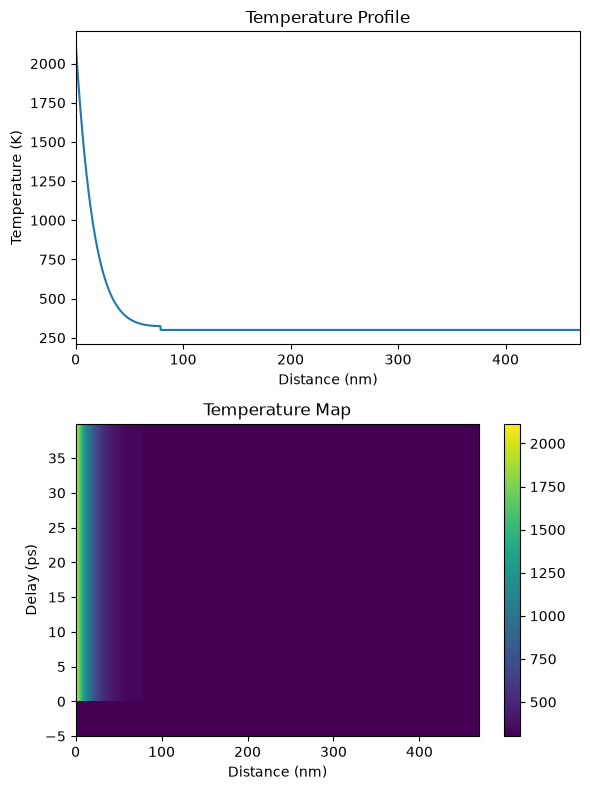

In [7]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.plot(distances.to("nm").magnitude, temp_map[101, :])
plt.xlim([0, distances.to("nm").magnitude[-1]])
plt.xlabel("Distance (nm)")
plt.ylabel("Temperature (K)")
plt.title("Temperature Profile")

plt.subplot(2, 1, 2)
plt.pcolormesh(distances.to("nm").magnitude, delays.to("ps").magnitude, temp_map, shading="auto")
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map")

plt.tight_layout()
plt.show()

## Numerical Phonons

Refer to the [strain pulse example](#example_strain_pulses) for more details.

In [8]:
p = ud.PhononNum(S, True)
p.save_data = False
p.disp_messages = True

In [9]:
strain_map = p.get_strain_map(delays, temp_map, delta_temp_map)

Calculating linear thermal expansion ...
Calculating coherent dynamics with ODE solver ...


0it [00:00, ?it/s]

Elapsed time for _strain_map_: 0.582724 s


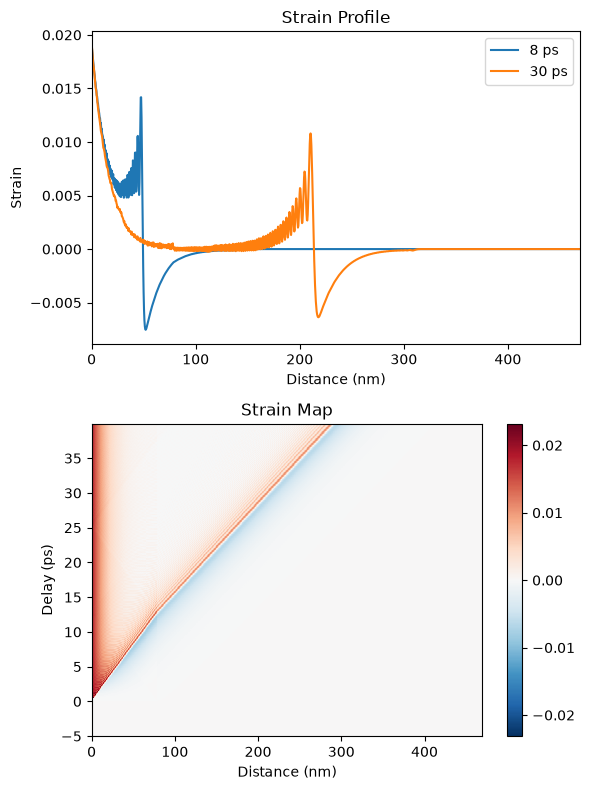

In [10]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.plot(distances.to("nm").magnitude, strain_map[130, :], label=np.round(delays[130]))
plt.plot(distances.to("nm").magnitude, strain_map[350, :], label=np.round(delays[350]))
plt.xlim([0, distances.to("nm").magnitude[-1]])
plt.xlabel("Distance (nm)")
plt.ylabel("Strain")
plt.legend()
plt.title("Strain Profile")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    distances.to("nm").magnitude,
    delays.to("ps").magnitude,
    strain_map,
    cmap="RdBu_r",
    vmin=-np.max(strain_map),
    vmax=np.max(strain_map),
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Strain Map")

plt.tight_layout()
plt.show()

## Dynamical X-ray Simulation

The {py:class}`XrayDyn <udkm1Dsim.simulations.scattering.dynamical.XrayDyn>` simulation is initialized as all other simulations, see the [scattering overview](#example_scattering_overview) for its experiment parameters and polarizations.

In [11]:
dyn = ud.XrayDyn(S, True)
dyn.disp_messages = True
dyn.save_data = False

## Homogeneous X-ray scattering

For the case of homogeneously strained samples, the dynamical X-ray scattering simulations can be greatly simplified, which saves a lot of computational time.

### $q_z$-scan

The reflectivity has a first dimension for the photon energies and a second for the scattering vectors $q_z$, see the experiment parameters in the [scattering overview](#example_scattering_overview).

In [12]:
dyn.energy = np.r_[5000, 8047] * u.eV  # set two photon energies
dyn.qz = np.r_[3.1:3.3:0.00001] / u.angstrom  # qz range

R_hom, A = dyn.homogeneous_reflectivity()  # this is the actual calculation

Calculating _homogenous_reflectivity_ ...
Elapsed time for _homogenous_reflectivity_: 1.882638 s


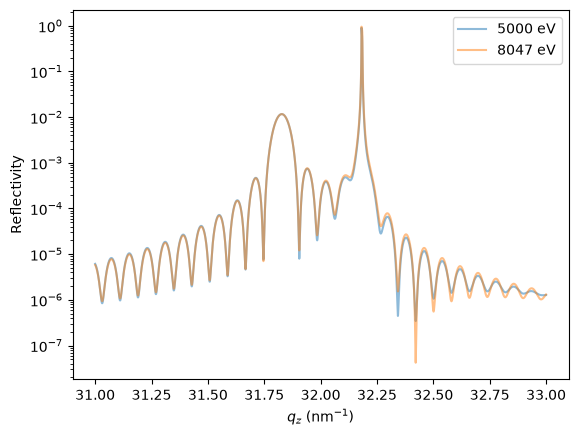

In [13]:
plt.figure()
plt.semilogy(dyn.qz[0, :], R_hom[0, :], label=f"{dyn.energy[0]}", alpha=0.5)
plt.semilogy(dyn.qz[1, :], R_hom[1, :], label=f"{dyn.energy[1]}", alpha=0.5)
plt.ylabel("Reflectivity")
plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.legend()
plt.show()

Due to the very thick static `substrate` in the {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` and the very small step width in `qz` also the Darwin width of the substrate Bragg peak is nicely resolvable. 

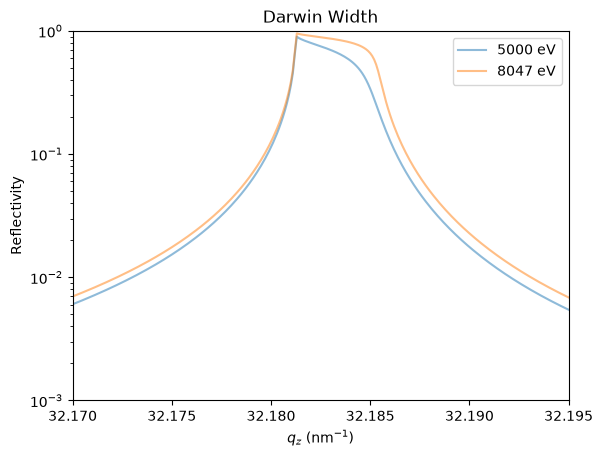

In [14]:
plt.figure()
plt.semilogy(dyn.qz[0, :], R_hom[0, :], label=f"{dyn.energy[0]}", alpha=0.5)
plt.semilogy(dyn.qz[1, :], R_hom[1, :], label=f"{dyn.energy[1]}", alpha=0.5)
plt.ylabel("Reflectivity")
plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.xlim(32.17, 32.195)
plt.ylim(1e-3, 1)
plt.legend()
plt.title("Darwin Width")
plt.show()

### Post-Processing

All result can be convoluted with an arbitrary function handle, which e.g. mimics the instrumental resolution.

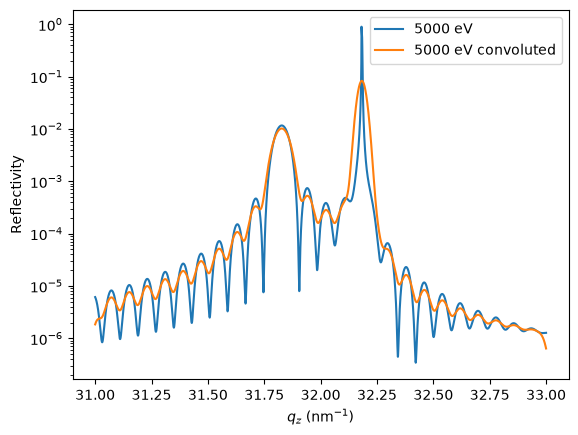

In [15]:
FWHM = 0.004 / 1e-10  # Angstrom
sigma = FWHM / 2.3548

handle = lambda x: np.exp(-(((x) / sigma) ** 2) / 2)
y_conv = dyn.conv_with_function(R_hom[0, :], dyn.experiment.qz.magnitude[0, :], handle)

plt.figure()
plt.semilogy(dyn.qz[0, :], R_hom[0, :], label=f"{dyn.energy[0]}")
plt.semilogy(dyn.qz[0, :], y_conv, label=f"{dyn.energy[0]} convoluted")
plt.ylabel("Reflectivity")
plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.legend()
plt.show()

### Energy-scan

Energy scans rely on the tabulated atomic form factors, which also include the energy ranges around the absorption edges.

Calculating _homogenous_reflectivity_ ...
Elapsed time for _homogenous_reflectivity_: 0.225121 s


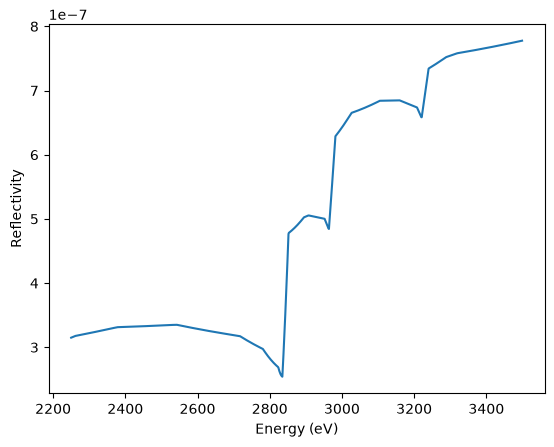

In [16]:
dyn.qz = np.r_[1.0] / u.angstrom  # qz range
dyn.energy = np.r_[2250:3500] * u.eV  # set the energy range

R_hom, A = dyn.homogeneous_reflectivity()  # this is the actual calculation

plt.figure()
plt.plot(dyn.energy, R_hom[:, 0])
plt.ylabel("Reflectivity")
plt.xlabel("Energy (eV)")
plt.show()

## Inhomogeneous X-ray scattering

The {py:meth}`inhomogeneous_reflectivity <udkm1Dsim.simulations.scattering.dynamical.XrayDyn.inhomogeneous_reflectivity>` method allows to calculate the transient X-ray reflectivity according to a `strain_map`.

The strains of the layers can be discretized by the `strain_vectors` to save computational time.

:::{versionadded} 2.3.0
The `strain_vectors` are optional, which allows to compare the computational speed of both approaches.
:::

Without `strain_vectors`, the reflectivity is calculated exactly for every {py:class}`UnitCell <udkm1Dsim.structures.layers.UnitCell>` and the exact values of the `strain_map`.

In [17]:
dyn.energy = np.r_[8047] * u.eV
dyn.qz = np.r_[3.1:3.3:0.001] / u.angstrom  # qz range

strain_vectors = p.get_reduced_strains_per_unique_layer(strain_map)
R_seq = dyn.inhomogeneous_reflectivity(strain_map, strain_vectors, calc_type="sequential")

Calculating _inhomogeneousReflectivity_ ...
Calculate all _ref_trans_matrices_ ...
Elapsed time for _ref_trans_matrices_: 0.482317 s


Progress:   0%|          | 0/450 [00:00<?, ?it/s]

Elapsed time for _inhomogeneous_reflectivity_: 17.113850 s


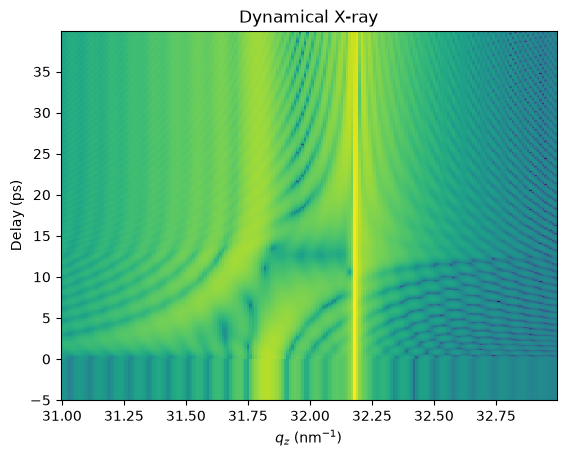

In [18]:
plt.figure()
plt.pcolormesh(
    dyn.qz[0, :].to("1/nm").magnitude,
    delays.to("ps").magnitude,
    np.log10(R_seq[:, 0, :]),
    shading="auto",
)
plt.title("Dynamical X-ray")
plt.ylabel("Delay (ps)")
plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.show()

The results can be convoluted again to mimic real experimental resolution:

In [19]:
R_seq_conv = np.zeros_like(R_seq)
for i, delay in enumerate(delays):
    R_seq_conv[i, 0, :] = dyn.conv_with_function(
        R_seq[i, 0, :], dyn.experiment.qz.magnitude[0, :], handle
    )

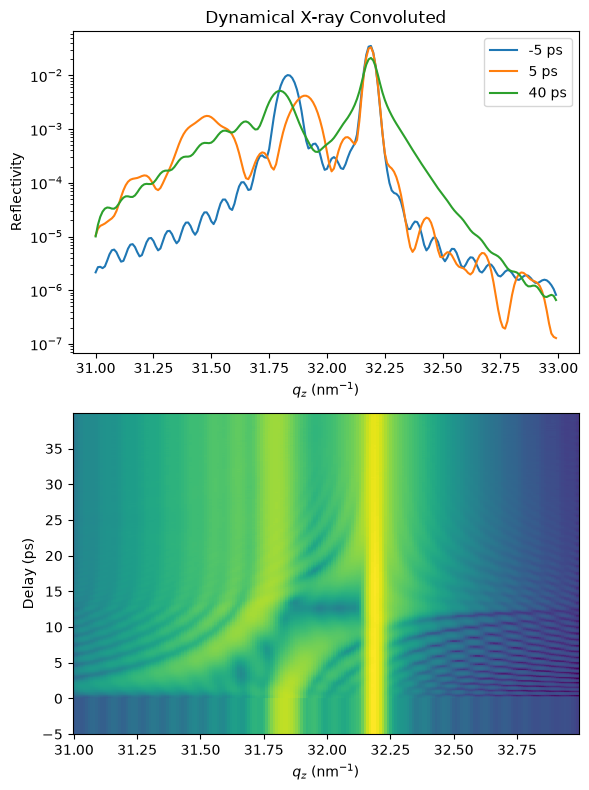

In [20]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.semilogy(dyn.qz[0, :].to("1/nm"), R_seq_conv[0, 0, :], label=np.round(delays[0]))
plt.semilogy(dyn.qz[0, :].to("1/nm"), R_seq_conv[100, 0, :], label=np.round(delays[100]))
plt.semilogy(dyn.qz[0, :].to("1/nm"), R_seq_conv[-1, 0, :], label=np.round(delays[-1]))

plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title("Dynamical X-ray Convoluted")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    dyn.qz[0, :].to("1/nm").magnitude,
    delays.to("ps").magnitude,
    np.log10(R_seq_conv[:, 0, :]),
    shading="auto",
)
plt.ylabel("Delay (ps)")
plt.xlabel("$q_z$ (nm$^{-1}$)")

plt.tight_layout()
plt.show()

## Parallel Inhomogeneous X-ray Scattering

The delays can be calculated in parallel with [Dask](https://docs.dask.org/en/latest/), which requires the `parallel` option of the **udkm1Dsim** toolbox, e.g. by `pip install udkm1Dsim[parallel]`.

In [21]:
try:
    from dask.distributed import Client

    client = Client(threads_per_worker=1)  # one worker per CPU core
    R_par = dyn.inhomogeneous_reflectivity(
        strain_map, strain_vectors, calc_type="parallel", dask_client=client
    )
    client.close()
except ImportError:
    pass

Calculating _inhomogeneousReflectivity_ ...
Calculate all _ref_trans_matrices_ ...
Elapsed time for _ref_trans_matrices_: 0.498079 s


Progress:   0%|          | 0/450 [00:00<?, ?it/s]

Elapsed time for _inhomogeneous_reflectivity_: 7.753519 s


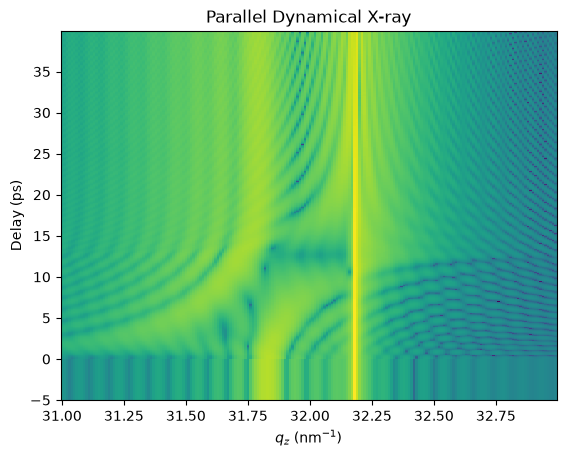

In [22]:
plt.figure()
plt.pcolormesh(
    dyn.qz[0, :].to("1/nm").magnitude,
    delays.to("ps").magnitude,
    np.log10(R_par[:, 0, :]),
    shading="auto",
)
plt.title("Parallel Dynamical X-ray")
plt.ylabel("Delay (ps)")
plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.show()